# Motifs from contribution scores

A sequence model's contribution scores show which bases it relied on for
each prediction, and the short stretches of high contribution, or seqlets,
hold the sites of the factors it has learned about. TF-MoDISco gathers
seqlets that look alike into patterns. This guide finds the same motifs a
different way, by calling seqlets and running motif discovery on their
letters, with [`contribution_motifs()`][universalmotif.contribution_motifs]
doing every step in one call. We use the chromBPNet model of chromatin
accessibility in K562 cells from the
[motifs and deep learning](deep-learning.ipynb) guide, and set what we find
beside the model's own TF-MoDISco patterns.

In [1]:
import pathlib
import tarfile
import time
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need the regions the model was interpreted on, its contribution scores,
the sequence of chromosome 1 from the UCSC Genome Browser, and, to compare
with, the model's TF-MoDISco results and the JASPAR 2024 vertebrate motifs.
The contribution scores are a bigWig track of 2.1 GB. The deep learning
guide reads a single region of it from ENCODE's server, but reading
thousands of regions that way takes hours, so here the track is downloaded
once into the cache, like the other files:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
scores_path = fetch(f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig")
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
chr1_path = fetch("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr1.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

## The regions

The model was interpreted on 1 kb windows around accessible regions. We
take those on chromosome 1, keep the middle 500 bases of each, where the
contributions are, and drop any that overlap one kept before, so that no
base is counted twice:

In [3]:
regions = um.read_bed(regions_path).filter(pl.col("chrom") == "chr1").sort("start")
mid = (regions["start"] + regions["end"]) // 2
windows = pl.DataFrame({"chrom": "chr1", "start": mid - 250, "end": mid + 250})
keep, last = [], -1
for s, e in windows.select("start", "end").iter_rows():
    if s >= last:
        keep.append(True)
        last = e
    else:
        keep.append(False)
windows = windows.filter(pl.Series(keep))
print(regions.height, "regions,", windows.height, "windows kept")

31165 regions, 21292 windows kept


[`signal_values()`][universalmotif.signal_values] reads the score of every
base of each window from the track, and the windows' sequences come from
chromosome 1 with [`extract_ranges()`][universalmotif.extract_ranges]:

In [4]:
chr1 = um.read_fasta(chr1_path)
seqs = list(um.extract_ranges(chr1, windows).values())
seqs = [s.upper() for s in seqs]
scores = np.stack([um.signal_values(scores_path, c, s, e) for c, s, e in windows.iter_rows()])
scores.shape

(21292, 500)

## Seqlets

[`call_seqlets()`][universalmotif.call_seqlets] calls a stretch a seqlet
when its total contribution is unlikely under a null built from all the
scores, and so is the total of every stretch inside it, so that a seqlet
holds no run of unremarkable bases. Seqlets are kept down to an estimated
false discovery rate of 20%:

In [5]:
t = time.time()
seqlets = um.call_seqlets(scores, seqs, seed=1, nthreads=2)
print(f"{time.time() - t:.1f} s")
seqlets.group_by("sign").agg(pl.len(), pl.col("end").sub(pl.col("start")).median().alias("median width"))

2.4 s


sign,len,median width
str,u32,f64
"""-""",112461,13.0
"""+""",16321,17.0


The false discovery rate comes from calling seqlets the same way in each
window's scores shuffled, which keeps the scores' values but not how the
model treats sequence with no sites. The model's own scores for shuffled
sequences, given as `decoys`, make a better null; we don't have the model
here, so we keep the default. Negative seqlets, where bases lower the
prediction, come out far more numerous than positive ones, which says
more about this null than about the model: most are faint, and the
shuffled scores are too lenient a null for them.

## Finding the motifs

[`contribution_motifs()`][universalmotif.contribution_motifs] takes the
scores and their sequences and does the rest: it calls seqlets,
searches their letters with [`motif_finder()`][universalmotif.motif_finder]
against windows of the same widths away from any seqlet, rebuilds each
motif from its hits in the seqlets with
[`refine_motifs()`][universalmotif.refine_motifs], and keeps those that
reach enough of the seqlets with
[`select_motifs()`][universalmotif.select_motifs], leaving out motifs whose
CWMs repeat another's. The positive seqlets are searched by default:

In [6]:
t = time.time()
found = um.contribution_motifs(scores, seqs, seed=1, nthreads=2)
print(f"{found!r} in {time.time() - t:.1f} s")
found.motifs.select("name", "consensus", "width", "seqlets", "gain", "cumulative")

ContributionMotifs(25 motifs from 16,321 seqlets) in 6.5 s


name,consensus,width,seqlets,gain,cumulative
str,str,i64,i64,f64,f64
"""pos_1""","""CCASYAGRKGGCRS""",14,2589,0.15863,0.15863
"""pos_2""","""GCYCCGCCCCC""",11,2402,0.138411,0.297041
"""pos_5""","""NTGACTCAB""",9,1509,0.091355,0.388395
"""pos_4""","""YCTTATCT""",8,1265,0.076098,0.464494
"""pos_11""","""ACTTCCTSTTY""",11,724,0.039581,0.504075
"""pos_13""","""MTGATGCAAY""",10,441,0.025672,0.529747
"""pos_12""","""RGCCAATSRGNR""",12,444,0.025427,0.555174
"""pos_28""","""RRACTACANYTCCCAGNAKSCNNNGC""",26,471,0.018381,0.573556
"""pos_10""","""SAGGRGGCGS""",10,1237,0.014828,0.588383


Each motif comes as a PPM in the `motif` column and as a CWM in the `cwm`
column, the mean contribution of each letter at its hits in the seqlets.
`seqlets` counts the seqlets its hits reach, `gain` the share of all of
them it adds to those reached by the motifs above it, and `cumulative` the
share reached so far. Here are the CWMs of the first eight:

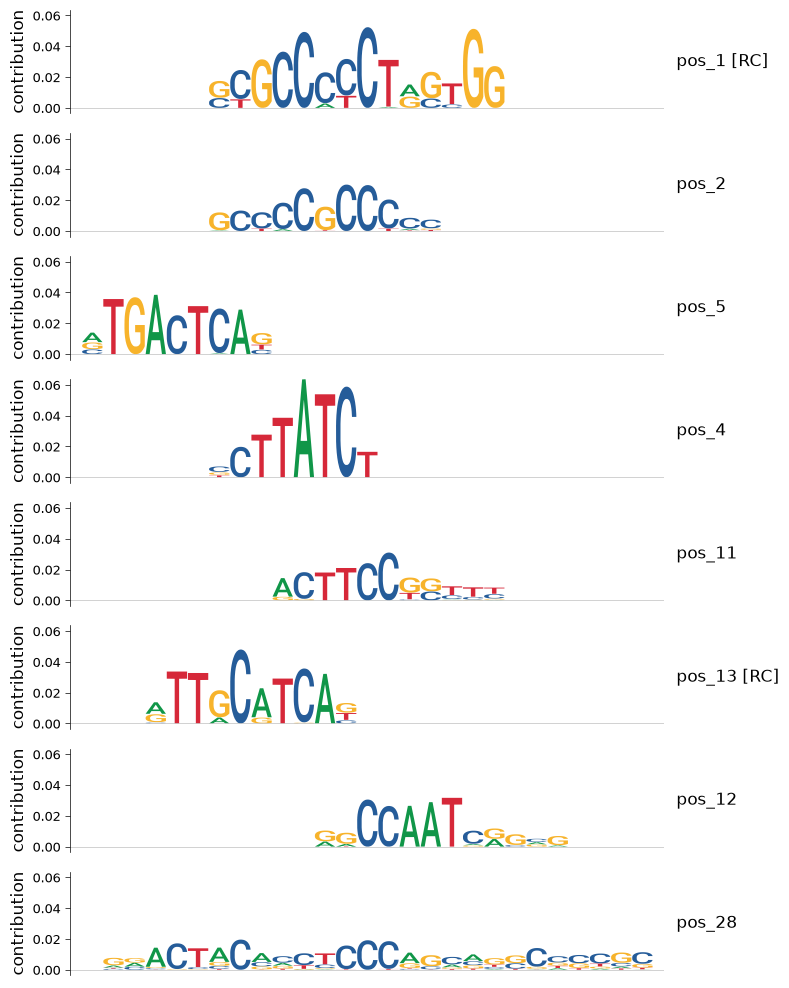

In [7]:
fig = um.view_motifs(found.cwms[:8], names_pos="right", show_positions=False, figsize=(8, 10))

## Naming the motifs

The model's TF-MoDISco patterns, read with
[`read_modisco()`][universalmotif.read_modisco], were found in all 270,000
regions rather than the 9,000 or so of chromosome 1 we used. We compare
the CWMs with those of the positive patterns, keeping the best match of
each, and name the patterns by their best JASPAR match as in the deep
learning guide:

In [8]:
def pattern_name(m):
    return m.replace(name=f"pattern_{m.name.rsplit('_', 1)[1]}")

modisco = [pattern_name(m) for m in um.read_modisco(modisco_path) if m.name.startswith("pos")]
cmp = um.compare_motifs(found.cwms + modisco, compare_to=list(range(len(found))), qvalue=1, nthreads=2)
best = (cmp.filter(pl.col("target_i") >= len(found)).sort("score", descending=True)
        .group_by("subject", maintain_order=True).first())

jaspar = um.read_meme(jaspar_path)
tf = {m.name: m.altname for m in jaspar}
ppms = [pattern_name(m) for m in um.read_modisco(modisco_path, type="PPM", trim_threshold=0.2)
        if m.name.startswith("pos")]
named = um.compare_motifs(ppms + jaspar, compare_to=list(range(len(ppms))), qvalue=0.05, complete=True, nthreads=2)
names = dict(named.filter(pl.col("target_i") >= len(ppms)).sort("qvalue").group_by("subject", maintain_order=True)
             .first().select("subject", tf=pl.col("target").replace_strict(tf)).iter_rows())
(
    found.motifs.select("name", "consensus", "seqlets")
    .join(best.select(name="subject", pattern="target", cosine="score"), on="name", how="left")
    .with_columns(tf=pl.col("pattern").replace_strict(names, default=None), cosine=pl.col("cosine").round(2))
)

name,consensus,seqlets,pattern,cosine,tf
str,str,i64,str,f64,str
"""pos_1""","""CCASYAGRKGGCRS""",2589,"""pattern_1""",1.0,"""CTCF"""
"""pos_2""","""GCYCCGCCCCC""",2402,"""pattern_2""",0.99,"""KLF16"""
"""pos_5""","""NTGACTCAB""",1509,"""pattern_3""",0.98,"""Bach1::Mafk"""
"""pos_4""","""YCTTATCT""",1265,"""pattern_0""",0.97,"""GATA2"""
"""pos_11""","""ACTTCCTSTTY""",724,"""pattern_8""",0.96,"""SPIB"""
"""pos_13""","""MTGATGCAAY""",441,"""pattern_7""",0.99,"""ATF4"""
"""pos_12""","""RGCCAATSRGNR""",444,"""pattern_5""",0.98,"""NFYA"""
"""pos_28""","""RRACTACANYTCCCAGNAKSCNNNGC""",471,"""pattern_12""",0.95,"""Thap11"""
"""pos_10""","""SAGGRGGCGS""",1237,"""pattern_21""",0.84,"""CTCF"""


Sixteen of the 25 motifs match one of the TF-MoDISco patterns with a
cosine of 0.9 or more, and between them they find 14 different patterns:
besides the four commonest, the CTCF site, the GC box of the SP and KLF
factors, the MAF recognition element of NF-E2 (named after its closest
JASPAR motif, BACH1::MAFK) and the GATA site, there are the sites of ETS
factors, ATF4, NF-Y, NRF1, STAT, ZBTB33 and THAP11, the last a pattern 26
bases wide that our motif spans whole. Several others are further
spellings of the commonest patterns, such as four GC-rich motifs close to
the GC box, which each reach seqlets the others miss. The one with no good
match, `pos_50`, holds `GGTTCGAATCC`, which looks like the B box of tRNA
genes, a promoter element of RNA polymerase III, and so a site the model
may have learned that TF-MoDISco did not report.

Missing is the model's NFI pattern, a palindrome of two half sites whose
letters vary too much for any one word of it to stand out. Finding it
needs the model's hypothetical scores, as shown below.

## Choosing the settings

The defaults aim at finding the patterns a model has learned, and keep a
motif when it adds at least 0.25% of the seqlets, even if it is similar to
others in its letters, as long as its CWM differs. For a short list of
motifs that between them reach as many seqlets as possible, such as for
scanning new sequences, keep motifs that add at least 1% and drop the CWM
comparison:

In [9]:
short = um.contribution_motifs(scores, seqs, seed=1, nthreads=2, min_gain=0.01, max_similarity=None)
short.motifs.select("name", "consensus", "seqlets", "gain", "cumulative")

name,consensus,seqlets,gain,cumulative
str,str,i64,f64,f64
"""pos_1""","""CCASYAGRKGGCRS""",2589,0.15863,0.15863
"""pos_2""","""GCYCCGCCCCC""",2402,0.138411,0.297041
"""pos_5""","""NTGACTCAB""",1509,0.091355,0.388395
"""pos_4""","""YCTTATCT""",1265,0.076098,0.464494
"""pos_9""","""CTGATAAGR""",735,0.044115,0.508609
"""pos_11""","""ACTTCCTSTTY""",724,0.039152,0.547761
"""pos_13""","""MTGATGCAAY""",441,0.02555,0.57331
"""pos_12""","""RGCCAATSRGNR""",444,0.025366,0.598677
"""pos_17""","""RKGGGCGGGMC""",503,0.021629,0.620305


These 16 motifs reach 72% of the seqlets between them, against 69% for the
25 above, since motifs close to one another in their CWMs now stay, each
catching sites the others miss, while rarer motifs adding less than 1% of
the seqlets go.

Other options trade one thing for another:

- `stability=4` reruns each search on four random halves of the seqlets
  and keeps the motifs found again in at least three of them, which makes
  the motifs found in one set of regions more like those another set would
  give, at the cost of the rarest motifs, which half the seqlets may not
  hold often enough to be found.
- `hypothetical` takes the model's hypothetical scores, those of every
  letter at every position, and adds a second search on the seqlets
  rewritten in the letters the model prefers by
  [`idealize_sequences()`][universalmotif.idealize_sequences]. Degenerate
  sites, whose letters vary too much for any one word to be common, such as
  the spaced palindromes of NFI, are found this way, then rebuilt from the
  real sequences. The bigWig track holds only the scores of the bases
  present, so we cannot show it here; chromBPNet writes hypothetical scores
  to files that [`read_contributions()`][universalmotif.read_contributions]
  reads.
- `decoys` takes the model's scores for shuffled sequences, such as from
  [`shuffled_references()`][universalmotif.shuffled_references], for the
  seqlets' false discovery rate.
- `sign="both"` searches the negative seqlets too.

With a model at hand, the extra inputs come from the same functions as in
the deep learning guide. This code is not run here, and `model` and
`attribute` stand for a model and a function giving its contribution
scores for one-hot sequences, observed and hypothetical:

```python
x = um.one_hot(seqs)
observed, hypothetical = attribute(model, x)
decoys, _ = attribute(model, um.shuffled_references(x, n=1, seed=1)[:, 0])
found = um.contribution_motifs(observed, seqs, hypothetical=hypothetical, decoys=decoys)
```

## Step by step

`contribution_motifs()` is a shortcut through functions that can each be
called on their own, for more control over any step. The search on the
seqlets' letters, for example, is an ordinary call to `motif_finder()`, and
its motifs can be refined and selected with the seqlets as the sites they
should reach:

In [10]:
pos = seqlets.filter(pl.col("sign") == "+")
targets = [seqs[i][max(s - 3, 0):e + 3] for i, s, e in pos.select("sequence_i", "start", "end").iter_rows()]
plain = um.motif_finder(targets, nmotifs=20, seed=1, nthreads=2)
refined = um.refine_motifs(plain, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen = um.select_motifs(refined, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen.select("motif", "rank", "targets", "gain", "kept").head(10)

motif,rank,targets,gain,kept
str,u32,u64,f64,bool
"""motif_1""",1,2299,0.140861,true
"""motif_3""",2,1904,0.113167,true
"""motif_2""",3,1752,0.106734,true
"""motif_4""",4,1553,0.093499,true
"""motif_5""",5,921,0.054225,true
"""motif_6""",6,654,0.036762,true
"""motif_11""",7,1148,0.028001,true
"""motif_12""",8,482,0.027265,true
"""motif_9""",9,492,0.025918,true


Here the background is three shuffles of the seqlets, the default when none
is given, where `contribution_motifs()` draws windows from the regions
away from any seqlet, which keeps the motifs common to all accessible
regions, such as their GC-rich stretches, from looking enriched.

## Matching the motifs to the scores

The CWMs can be matched against contribution scores with
[`scan_contributions()`][universalmotif.scan_contributions], which finds
the sites the model relied on rather than every site that looks like a
motif. Here we match them in the first 3,000 windows and look at the one
with the most different motifs:

In [11]:
hits = um.scan_contributions(found.cwms, scores[:3000], sequences=seqs[:3000],
                             no_overlaps_across_motifs=True, nthreads=2)
row = int(hits.group_by("sequence_i").agg(pl.col("motif").n_unique().alias("n"))
          .sort("n", "sequence_i", descending=[True, False])["sequence_i"][0])
here = hits.filter(pl.col("sequence_i") == row)
here.select("motif", "start", "end", "strand", "match", "similarity", "importance")

motif,start,end,strand,match,similarity,importance
str,i64,i64,str,str,f64,f64
"""pos_5""",174,183,"""-""","""CTGACTCAT""",0.979089,0.32399
"""pos_10""",338,348,"""+""","""AAGATGGCGA""",0.764363,0.174152
"""pos_7""",271,278,"""-""","""GTTACGG""",0.820687,0.107513
"""pos_29""",289,299,"""+""","""GATCCTCCCC""",0.789406,0.082001
"""pos_21""",244,254,"""+""","""GTGACGTGTG""",0.801775,0.142216
"""pos_41""",101,109,"""-""","""TTATCATT""",0.875828,0.084458
"""pos_43""",208,220,"""+""","""GGCCACGTGGCT""",0.866788,0.17672
"""pos_46""",229,239,"""-""","""CCCCTCCCGG""",0.735753,0.173652


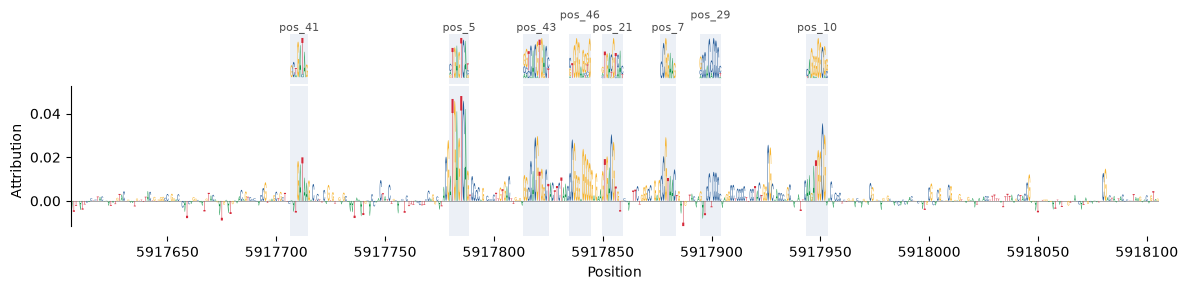

In [12]:
c, s, e = windows.row(row)
ax = um.view_attributions(scores[row], seqs[row], start=s, hits=here, motifs=found.cwms, figsize=(12, 3))